# NeuroSignal AI — Pipeline
## 0. Setup

In [7]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

from src import config
print(config.ROOT)
print("Raw data found:", config.RAW_DIR.exists())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
\\192.168.0.100\Shruti\ASHRUTI\Projects\neurosignal-ai
Raw data found: True


In [8]:
import warnings
warnings.filterwarnings("ignore", message="Channel names are not unique")

from src.labels import load_all_labels
labels = load_all_labels()
print(len(labels), "seizures,", labels["duration"].sum(), "seconds of seizure")
labels

22 seizures, 1574 seconds of seizure


,patient,file,start,end,duration
0,chb01,chb01_03.edf,2996,3036,40
1,chb01,chb01_04.edf,1467,1494,27
2,chb01,chb01_15.edf,1732,1772,40
3,chb01,chb01_16.edf,1015,1066,51
4,chb01,chb01_18.edf,1720,1810,90
5,chb01,chb01_21.edf,327,420,93
6,chb01,chb01_26.edf,1862,1963,101
7,chb02,chb02_16.edf,130,212,82
8,chb02,chb02_16+.edf,2972,3053,81
9,chb02,chb02_19.edf,3369,3378,9


In [9]:
import mne
total_seconds = sum(
    mne.io.read_raw_edf(f, preload=False, verbose=False).n_times / 256
    for f in config.RAW_DIR.glob("*.edf")
)
seizure_pct = labels["duration"].sum() / total_seconds * 100
print(f"Total: {total_seconds/3600:.2f} h | Seizure share: {seizure_pct:.2f}%")

Total: 28.91 h | Seizure share: 1.51%


## 2. Preprocessing check
Compare the power spectrum before and after the 0.5–40 Hz band-pass filter.
The 60 Hz mains spike should disappear. The figure is saved to `docs/` for the README.

21 channels: ['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'T7-FT9', 'FT9-FT10', 'FT10-T8']
Plotting power spectral density (dB=True).


C:\Users\Shruti\AppData\Local\Temp\ipykernel_23996\240628105.py:12: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw_before.compute_psd(fmax=80, verbose=False).plot(axes=axes[0], show=False)


Plotting power spectral density (dB=True).


C:\Users\Shruti\AppData\Local\Temp\ipykernel_23996\240628105.py:13: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw_after.compute_psd(fmax=80, verbose=False).plot(axes=axes[1], show=False)


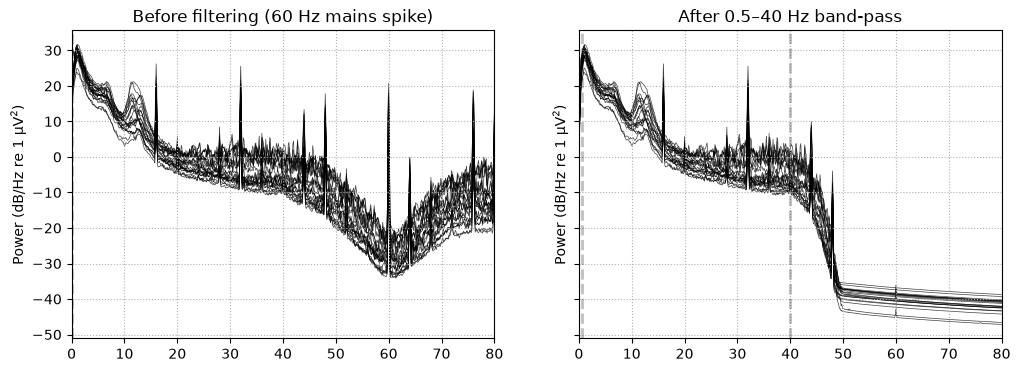

In [ ]:
import mne
import matplotlib.pyplot as plt
from src.preprocess import load_raw

# Same file, raw versus cleaned
raw_before = mne.io.read_raw_edf(config.RAW_DIR / "chb01_03.edf", preload=True, verbose=False)
raw_after = load_raw("chb01_03.edf")
print(len(raw_after.ch_names), "channels:", raw_after.ch_names)  # expect 21

# Side-by-side power spectra, same y-axis for a fair comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
raw_before.compute_psd(fmax=80, verbose=False).plot(axes=axes[0], show=False)
raw_after.compute_psd(fmax=80, verbose=False).plot(axes=axes[1], show=False)
axes[0].set_title("Before filtering (raw)")
axes[1].set_title("After 0.5–40 Hz band-pass")

# Save as README evidence
fig.savefig(config.DOCS_DIR / "psd_before_after.png", dpi=120, bbox_inches="tight")
plt.show()